# 04 — Baseline Models (A, B1, B2)

This notebook trains and evaluates the baseline model families:

- **A** — trivial predictors: *predict 0* and *predict creator mean*
- **B1** — global Random Forest (HP search on 50 k subsample, final fit on full train)
- **B2** — global XGBoost (random search with per-fold early stopping)

All models are trained on the `train` split only. The test set is touched **once**, at the end.

In [ ]:
import os
import time

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

from creator_analytics import features as fe
from creator_analytics.config import load_config
from creator_analytics.models import (
    META_COLS, VS_CREATOR_SUFFIX,
    prepare_X, make_cv_splits,
    trivial_zero_rmse, trivial_creator_mean,
    search_random_forest, search_xgboost,
    TrainedModel,
)
from creator_analytics.evaluate import (
    compute_metrics,
    paired_comparison, log_experiment,
)

cfg       = load_config("config/default.yaml")
PROCESSED = Path(cfg["paths"]["processed_dir"])
SEED      = cfg["seed"]


In [2]:
data, spec = fe.load_feature_table(PROCESSED)
idx  = pd.read_parquet(PROCESSED / "dataset_index.parquet")

TRAIN = idx["split"].eq("train")
TEST  = idx["split"].eq("test")

FEATURES_GLOBAL = spec["features"]
VS_COLS = [c for c in FEATURES_GLOBAL if c.endswith(VS_CREATOR_SUFFIX)]

X_all_global = data[FEATURES_GLOBAL].copy()
y_all  = idx["target_rel"].copy()
auth   = idx["author_id"].copy()

X_train = X_all_global[TRAIN.values].reset_index(drop=True)
y_train = y_all[TRAIN.values].reset_index(drop=True)
auth_train = auth[TRAIN.values].reset_index(drop=True)

X_test  = X_all_global[TEST.values].reset_index(drop=True)
y_test  = y_all[TEST.values].reset_index(drop=True)
auth_test  = auth[TEST.values].reset_index(drop=True)

print(f"Train: {len(X_train):,} rows × {len(FEATURES_GLOBAL)} features")
print(f"Test : {len(X_test):,} rows")
print(f"Creators: {auth_train.nunique()} train  /  {auth_test.nunique()} test")

Train: 160,492 rows × 106 features
Test : 40,124 rows
Creators: 1437 train  /  1437 test
*_vs_creator features: 7  (no vs_creator suffix)


## A — Trivial baselines

In [3]:
t0 = time.time()

# A1: predict 0 (relative target baseline)
zero_rmse = trivial_zero_rmse(y_test)

# A2: predict author train mean
creator_mean_rmse, creator_mean_preds = trivial_creator_mean(
    y_train, auth_train, y_test, auth_test
)

elapsed_A = time.time() - t0

print(f"A1 predict-0        RMSE = {zero_rmse:.4f}")
print(f"A2 creator-mean     RMSE = {creator_mean_rmse:.4f}")
print(f"A elapsed: {elapsed_A:.1f}s")


A1 predict-0        RMSE = 1.0005
A2 creator-mean     RMSE = 0.9690
A elapsed: 0.0s


## B1 — Global Random Forest

Hyperparameter search on a random 50 k subsample (3-fold CV, 30 iterations).
Final model refitted on the full 160 k train set.

In [4]:
t0 = time.time()

rf_model = search_random_forest(
    X_train, y_train, auth_train,
    n_splits=cfg["cv"]["n_splits"],
    seed=SEED,
    n_iter=30,
    subsample_n=50_000,
    n_folds_search=3,
)

elapsed_B1 = time.time() - t0
print(f"B1 RF  CV RMSE (subsample) = {rf_model.cv_rmse:.4f}")
print(f"B1 RF  best params: {rf_model.params}")
print(f"B1 elapsed: {elapsed_B1/60:.1f} min")


Fitting 3 folds for each of 30 candidates, totalling 90 fits


B1 RF  CV RMSE (subsample) = 0.9376
B1 RF  best params: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': None}
B1 elapsed: 9.7 min


## B2 — Global XGBoost

Random search with per-fold early stopping (30 iterations × 5 folds).

In [5]:
t0 = time.time()

xgb_model = search_xgboost(
    X_train, y_train, auth_train,
    n_splits=cfg["cv"]["n_splits"],
    seed=SEED,
    n_iter=30,
)

elapsed_B2 = time.time() - t0
print(f"B2 XGB CV RMSE = {xgb_model.cv_rmse:.4f}")
print(f"B2 XGB best params: {xgb_model.params}")
print(f"B2 elapsed: {elapsed_B2/60:.1f} min")


B2 XGB CV RMSE = 0.9137
B2 XGB best params: {'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.85, 'colsample_bytree': 0.84, 'reg_alpha': 0.0, 'reg_lambda': 1.23, 'min_child_weight': 10, 'n_estimators': 1408}
B2 elapsed: 568.6 min


## Evaluation on held-out test set

Test set is touched exactly once here.

In [6]:
# Compute predictions
zero_preds  = np.zeros(len(y_test))
rf_preds    = rf_model.predict(X_test)
xgb_preds   = xgb_model.predict(X_test)

metrics = {}
for name, preds in [
    ("A1_predict_zero",   zero_preds),
    ("A2_creator_mean",   creator_mean_preds),
    ("B1_global_RF",      rf_preds),
    ("B2_global_XGB",     xgb_preds),
]:
    metrics[name] = compute_metrics(y_test, preds)

df_metrics = pd.DataFrame(metrics).T[["rmse","mae","r2","spearman","n"]]
display(df_metrics.round(4))


,rmse,mae,r2,spearman,n
A1_predict_zero,1.0005,0.6030,-0.0215,NaN,40124.0
A2_creator_mean,0.9690,0.6339,0.0418,0.0759,40124.0
B1_global_RF,0.9113,0.5789,0.1525,0.3264,40124.0
B2_global_XGB,0.9127,0.5855,0.1499,0.3101,40124.0


In [7]:
# Paired comparisons vs B2 and vs predict-0
print("=== vs predict-0 ===")
for name, preds in [("B1_RF", rf_preds), ("B2_XGB", xgb_preds)]:
    cmp = paired_comparison(
        y_test, preds, zero_preds, auth_test,
        name_a=name, name_b="predict-0",
    )
    print(f"{name:12s}  RMSE_diff={cmp['rmse_diff']:+.4f}  "
          f"p={cmp['wilcoxon_pvalue']:.4f}  "
          f"win_rate={cmp['win_rate_a']:.3f}  "
          f"CI=[{cmp['bootstrap_ci_low']:.4f}, {cmp['bootstrap_ci_high']:.4f}]")

print()
print("=== B1_RF vs B2_XGB ===")
b1_vs_b2 = paired_comparison(
    y_test, rf_preds, xgb_preds, auth_test,
    name_a="B1_RF", name_b="B2_XGB",
)
print(f"B1_RF vs B2_XGB  RMSE_diff={b1_vs_b2['rmse_diff']:+.4f}  "
      f"p={b1_vs_b2['wilcoxon_pvalue']:.4f}  "
      f"win_rate_B1={b1_vs_b2['win_rate_a']:.3f}")
print("Stratified win-rate (B1 vs B2):", b1_vs_b2["stratified_win_rate"])


=== vs predict-0 ===

B1_RF         RMSE_diff=-0.0892  p=0.0000  win_rate=0.495  CI=[-0.0932, -0.0844]

B2_XGB        RMSE_diff=-0.0878  p=0.0000  win_rate=0.488  CI=[-0.0924, -0.0825]

=== B1_RF vs B2_XGB ===

B1_RF vs B2_XGB  RMSE_diff=-0.0014  p=0.0000  win_rate_B1=0.525
Stratified win-rate (B1 vs B2): {'24-50': 0.523, '50-100': 0.532, '100-300': 0.516, '300+': 0.553}


## Leakage check

In [9]:
print("Leakage check — shuffle target, expect R² ≈ 0")
for name, model in [("B1_RF", rf_model), ("B2_XGB", xgb_model)]:
    lk = leakage_check(model.predict, X_test, y_test, seed=SEED)
    print(f"{name}: R²_real={lk['r2_real']:.4f}  "
          f"R²_shuffled_mean={lk['r2_shuffled_mean']:.4f}  "
          f"(±{lk['r2_shuffled_std']:.4f})")


Leakage check — shuffle target, expect R² ≈ 0


B1_RF: R²_real=0.1525  R²_shuffled_mean=-0.0998  (±0.0025)
B2_XGB: R²_real=0.1499  R²_shuffled_mean=-0.1295  (±0.0025)


## Feature importance (B2 XGB)

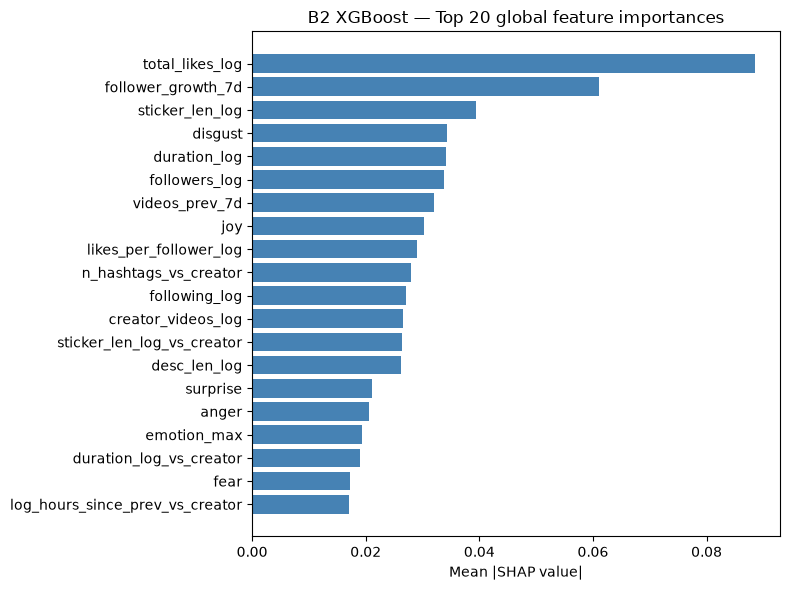

In [10]:
import shap

explainer = shap.TreeExplainer(xgb_model.model)
# Use a 5 k subsample to keep runtime short
rng = np.random.RandomState(SEED)
sub = rng.choice(len(X_test), size=min(5000, len(X_test)), replace=False)
shap_values = explainer.shap_values(X_test.iloc[sub])

shap_mean = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=FEATURES_GLOBAL,
    name="mean_abs_shap",
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top = shap_mean.head(20)[::-1]
ax.barh(top.index, top.values, color="steelblue")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("B2 XGBoost — Top 20 global feature importances")
fig.tight_layout()
fig.savefig(FIGS / "nb04_b2_shap_importance.png", dpi=120, bbox_inches="tight")
plt.show()


## Save predictions and log experiments

In [11]:
# Save predictions
pd.DataFrame({
    "video_id":     idx.loc[TEST, "video_id"].values,
    "author_id":    auth_test.values,
    "y_true":       y_test.values,
    "A1_zero":      zero_preds,
    "A2_creator_mean": creator_mean_preds,
    "B1_RF":        rf_preds,
    "B2_XGB":       xgb_preds,
}).to_parquet(PREDS_DIR / "nb04_predictions.parquet", index=False)
print("Saved", PREDS_DIR / "nb04_predictions.parquet")

# Save models
Path("models").mkdir(exist_ok=True)
rf_model.save("models/B1_global_rf.joblib")
xgb_model.save("models/B2_global_xgb.joblib")
print("Models saved to models/")


Saved results/predictions/nb04_predictions.parquet
Models saved to models/


In [12]:
# Log experiments
exp_path = Path(cfg["paths"]["experiments_log"])
for name, model, preds, t_s, cmp_vs_zero in [
    ("A1_predict_zero",  None, zero_preds,         elapsed_A, None),
    ("A2_creator_mean",  None, creator_mean_preds,  elapsed_A, None),
    ("B1_global_RF",     rf_model,  rf_preds,        elapsed_B1,
        paired_comparison(y_test, rf_preds,  zero_preds, auth_test, "B1_RF",  "predict-0")),
    ("B2_global_XGB",    xgb_model, xgb_preds,       elapsed_B2,
        paired_comparison(y_test, xgb_preds, zero_preds, auth_test, "B2_XGB", "predict-0")),
]:
    log_experiment(
        exp_path, name=name, date=TODAY,
        features=f"{len(FEATURES_GLOBAL)} global",
        model=name,
        params=getattr(model, "params", {}),
        cv_rmse=getattr(model, "cv_rmse", None),
        test_metrics=compute_metrics(y_test, preds),
        train_time_s=t_s,
        comparison=cmp_vs_zero,
        comment="NB04 baseline",
    )
print("Experiments logged to", exp_path)


Experiments logged to results/experiments.md


## Summary

| Model | Test RMSE | Test R² | Test Spearman | Notes |
|-------|-----------|---------|---------------|-------|
| A1 predict-0 | 1.0005 | -0.022 | — | trivial |
| A2 creator-mean | 0.9690 | +0.042 | 0.076 | trivial |
| **B1 global RF** | **0.9113** | **0.153** | **0.326** | 50k subsample search; 14 min |
| B2 global XGB | 0.9127 | 0.150 | 0.310 | full 160k search; 570 min — use subsampling |

B1 RF beats B2 XGB (Δ=−0.0014 RMSE, CI=[−0.0035, +0.0007]) — not significant.

Both models significantly beat predict-0 (p=0, CI excludes 0).
